# AR(3): minimized empirical width as the sample size increases

For one fixed AR(3) process, plot $T\mapsto\widehat m^{*}_{k,T}$ for $k\in\{2,3,4,5\}$, where

$$\widehat m^{*}_{k,T}=\widehat w_{k,T}(\widehat u_{k,T}),\qquad
\widehat w_{k,T}(u)=\max_{y\in\mathcal P_{k,T}} y^\top u-\min_{y\in\mathcal P_{k,T}}y^\top u,\qquad \|u\|_2=1.$$

Here $\widehat u_{k,T}$ is the best direction found by multistart projected subgradient descent. Width is piecewise linear, so this is the existing AR gradient-descent method with an active subgradient at a kink. The asterisk denotes the numerical optimizer's result; it does not certify a global minimum.

Use the simple, stationary coefficient vector $\phi=(0.6,-0.3,0.2)$ and innovations $\varepsilon_t\sim\operatorname{Unif}[-1,1]$:

$$X_t=0.6X_{t-1}-0.3X_{t-2}+0.2X_{t-3}+\varepsilon_t.$$

After a burn-in, simulate **one long path** and use nested prefixes of length $T$. Following the common-endpoint convention in the AR chapter, set $K=5$ and use $\mathcal P_{k,T}=\{(X_t,\ldots,X_{t-k+1}):t=K,\ldots,T\}$. Thus each dimension has exactly $T-K+1$ points, and $T$ is the number of retained time-series observations, not the number of optimizer steps. No sample-dependent rescaling is applied.

In [1]:
import sys
from pathlib import Path
from time import perf_counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "functions.py").is_file()
        and (candidate / "ar3_minimum_width_k4.ipynb").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.descent import (
    batched_geometric_width_curves,
)
from Code.Code_AR_processes.functions import (
    is_stationary,
    simulate_uniform_ar,
    sliding_window_point_cloud,
    theoretical_ar_width_in_direction,
)

EXPERIMENT_NAME = "ar3_minimum_width_vs_T"
CSV_DIR = AR_CODE_DIR / "outputs" / "csv" / EXPERIMENT_NAME
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / EXPERIMENT_NAME
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / EXPERIMENT_NAME
for directory in (CSV_DIR, PDF_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "pdf.fonttype": 42})
np.set_printoptions(precision=6, suppress=True)

## Experiment settings

Edit this cell to change the coefficients, sample-size grid, or descent budget. The same deterministic random starts are reused for a given $k$ at every $T$; the first start is the smallest-covariance eigenvector for that point cloud. All starts are optimized, and the smallest attained width is retained. The true AR direction is not used to initialize the estimator.

In [2]:
phi = np.array([0.6, -0.3, 0.2], dtype=float)
k_values = np.array([2, 3, 4, 5], dtype=int)
T_values = np.array([100, 200, 500, 1_000, 2_000, 5_000,
                     10_000, 20_000, 50_000], dtype=int)
K = int(k_values.max())
burnin = 2_000
innovations_half_width = 1.0
process_seed = 20260916
optimizer_seed = 20260917
number_of_starts = 12
optimization_iterations = 3_000
initial_step_scale = 0.2
geometric_decay = 0.995
population_history = 1_000

stationary, companion_eigenvalues = is_stationary(phi)
if len(phi) != 3 or phi[-1] == 0 or not stationary:
    raise ValueError("Choose a stationary, genuine AR(3) coefficient vector.")
if (T_values.ndim != 1 or len(T_values) < 2
        or np.any(np.diff(T_values) <= 0) or T_values[0] <= K):
    raise ValueError("T_values must be strictly increasing and exceed K.")
if (k_values.ndim != 1 or len(k_values) == 0
        or len(np.unique(k_values)) != len(k_values)
        or np.any(k_values < 2)):
    raise ValueError("k_values must contain distinct embedding dimensions >= 2.")
if number_of_starts < 1 or optimization_iterations < 1:
    raise ValueError("Use positive numbers of starts and iterations.")
if initial_step_scale <= 0 or not 0 < geometric_decay < 1:
    raise ValueError("Require initial_step_scale > 0 and 0 < geometric_decay < 1.")

ar3_series = simulate_uniform_ar(
    phi, sample_size=int(T_values[-1]), burnin=burnin,
    half_width=innovations_half_width, rng=process_seed,
)
population_plateau = (
    2.0 * innovations_half_width / np.sqrt(1.0 + phi @ phi)
)

print(f"Coefficients: {phi}")
print(f"Companion spectral radius: {max(abs(companion_eigenvalues)):.6f} < 1")
print(f"Sample sizes T: {T_values}")
print(f"Dimensions k: {k_values}; common endpoint K = {K}")
print(f"Starts: {number_of_starts}; iterations per start: {optimization_iterations}")
print(f"Population reference for k >= 4: {population_plateau:.8f}")

Coefficients: [ 0.6 -0.3  0.2]
Companion spectral radius: 0.628763 < 1
Sample sizes T: [  100   200   500  1000  2000  5000 10000 20000 50000]
Dimensions k: [2 3 4 5]; common endpoint K = 5
Starts: 12; iterations per start: 3000
Population reference for k >= 4: 1.63846384


## Minimize the width for every $(k,T)$

The optimizer uses the shared `batched_geometric_width_curves` implementation. For each dimension it runs all starts together with the sphere update

$$g_n=Y_{\max} - Y_{\min},\qquad g_n^{\mathrm{tan}}=g_n-(u_n^\top g_n)u_n,\qquad
u_{n+1}=\frac{u_n-\eta_n g_n^{\mathrm{tan}}}{\|u_n-\eta_n g_n^{\mathrm{tan}}\|_2}.$$

Set $\eta_n=(0.2/L^{\mathrm{box}}_{k,T})(0.995)^n$, where

$$L^{\mathrm{box}}_{k,T}=\left\|\max_{y\in\mathcal P_{k,T}}y-\min_{y\in\mathcal P_{k,T}}y\right\|_2\ge\operatorname{diam}(\mathcal P_{k,T}),$$

and the maxima/minima in this bound are componentwise. This gives an inexpensive Lipschitz upper bound without an $O(T^2)$ pairwise-distance calculation. The values in the settings cell control the schedule. The reported width is recomputed from the saved unit direction to check that the optimization result and point cloud agree.

In [3]:
experiment_rows = []
estimated_directions = {}
experiment_start = perf_counter()

# Small-dimensional matrix products are faster with one BLAS thread.
with threadpool_limits(limits=1):
    for T in T_values:
        T = int(T)
        for k in k_values:
            k = int(k)
            # In zero-based indexing, this slice makes all cloud endpoints
            # run from K - 1 through T - 1, with newest-first coordinates.
            series_for_k = ar3_series[K - k:T]
            cloud = sliding_window_point_cloud(series_for_k, k)
            if cloud.shape != (T - K + 1, k):
                raise RuntimeError("The common-endpoint embedding is inconsistent.")
            lipschitz_bound = float(np.linalg.norm(np.ptp(cloud, axis=0)))
            if not np.isfinite(lipschitz_bound) or lipschitz_bound <= 0:
                raise ValueError("The point cloud must have positive finite width.")
            initial_step = initial_step_scale / lipschitz_bound
            start_time = perf_counter()
            single_widths, best_widths, _, directions = (
                batched_geometric_width_curves(
                    series_for_k, [k], seed=optimizer_seed, replication=0,
                    starts=number_of_starts, iterations=optimization_iterations,
                    initial_step=initial_step, geometric_decay=geometric_decay,
                    return_directions=True,
                )
            )
            optimization_seconds = perf_counter() - start_time
            direction = directions[0]
            projections = cloud @ direction
            empirical_width = float(np.ptp(projections))
            if not np.isclose(np.linalg.norm(direction), 1.0, atol=1e-10):
                raise RuntimeError("The estimated direction is not a unit vector.")
            if not np.isclose(empirical_width, best_widths[0], atol=1e-10):
                raise RuntimeError("The saved direction does not reproduce the width.")
            population_width_at_estimate = theoretical_ar_width_in_direction(
                phi, direction, half_width=innovations_half_width,
                history=population_history,
            )
            estimated_directions[(k, T)] = direction.copy()
            row = {
                "T": T, "k": k, "point_count": len(cloud),
                "minimum_width": empirical_width,
                "covariance_start_width": float(single_widths[0]),
                "restart_improvement": float(single_widths[0] - empirical_width),
                "population_width_at_estimated_direction": population_width_at_estimate,
                "lipschitz_upper_bound": lipschitz_bound,
                "initial_step": initial_step,
                "optimization_seconds": optimization_seconds,
            }
            for coordinate in range(K):
                row[f"u_{coordinate}"] = (
                    float(direction[coordinate]) if coordinate < k else np.nan
                )
            experiment_rows.append(row)
        latest = experiment_rows[-len(k_values):]
        print(f"T = {T:>6,}: " + ", ".join(
            f"k={row['k']}: {row['minimum_width']:.6f}" for row in latest
        ), flush=True)

width_results = pd.DataFrame(experiment_rows).sort_values(["T", "k"])
width_table = width_results.pivot(index="T", columns="k", values="minimum_width")
width_results.to_csv(CSV_DIR / "width_results.csv", index=False)
width_table.to_csv(CSV_DIR / "width_vs_T.csv")
configuration = {
    "phi": phi.tolist(), "k_values": k_values.tolist(), "T_values": T_values.tolist(),
    "K": K, "burnin": burnin, "innovations_half_width": innovations_half_width,
    "process_seed": process_seed, "optimizer_seed": optimizer_seed,
    "number_of_starts": number_of_starts,
    "optimization_iterations": optimization_iterations,
    "initial_step_scale": initial_step_scale, "geometric_decay": geometric_decay,
    "population_history": population_history,
    "optimizer": "batched_geometric_width_curves",
    "step_normalization": "coordinate-box diameter upper bound",
    "embedding": "newest first, common endpoints t = K,...,T",
}
(CSV_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")
print(f"Total elapsed time: {perf_counter() - experiment_start:.1f} seconds")
display(width_table.round(6))

T =    100: k=2: 1.986227, k=3: 1.728086, k=4: 1.508891, k=5: 1.407747


T =    200: k=2: 1.986227, k=3: 1.783779, k=4: 1.551010, k=5: 1.464173


T =    500: k=2: 2.087440, k=3: 1.895339, k=4: 1.609061, k=5: 1.593173


T =  1,000: k=2: 2.198642, k=3: 1.948298, k=4: 1.617436, k=5: 1.605941


T =  2,000: k=2: 2.269467, k=3: 1.969251, k=4: 1.622613, k=5: 1.617210


T =  5,000: k=2: 2.298670, k=3: 2.032540, k=4: 1.634582, k=5: 1.634108


T = 10,000: k=2: 2.345934, k=3: 2.048289, k=4: 1.635493, k=5: 1.634976


T = 20,000: k=2: 2.373213, k=3: 2.098097, k=4: 1.637944, k=5: 1.637790


T = 50,000: k=2: 2.382370, k=3: 2.131526, k=4: 1.638390, k=5: 1.638161


Total elapsed time: 87.4 seconds


k,2,3,4,5
T,,,,
100,1.986227,1.728086,1.508891,1.407747
200,1.986227,1.783779,1.551010,1.464173
500,2.087440,1.895339,1.609061,1.593173
1000,2.198642,1.948298,1.617436,1.605941
2000,2.269467,1.969251,1.622613,1.617210
5000,2.298670,2.032540,1.634582,1.634108
10000,2.345934,2.048289,1.635493,1.634976
20000,2.373213,2.098097,1.637944,1.637790
50000,2.382370,2.131526,1.638390,1.638161


## Plot $T$ versus $\widehat m^{*}_{k,T}$

Both panels show the same four raw curves. The logarithmic $T$ axis makes changes at smaller sample sizes visible; the linear axis shows the large-$T$ behavior. The horizontal reference is

$$m_4=m_5=\frac{2}{\sqrt{1+0.6^2+(-0.3)^2+0.2^2}}.$$

This reference concerns $k\ge p+1=4$; it is not the population minimum for $k=2,3$. It is calculated from the configured coefficients and innovation support, and is not used by the estimator.

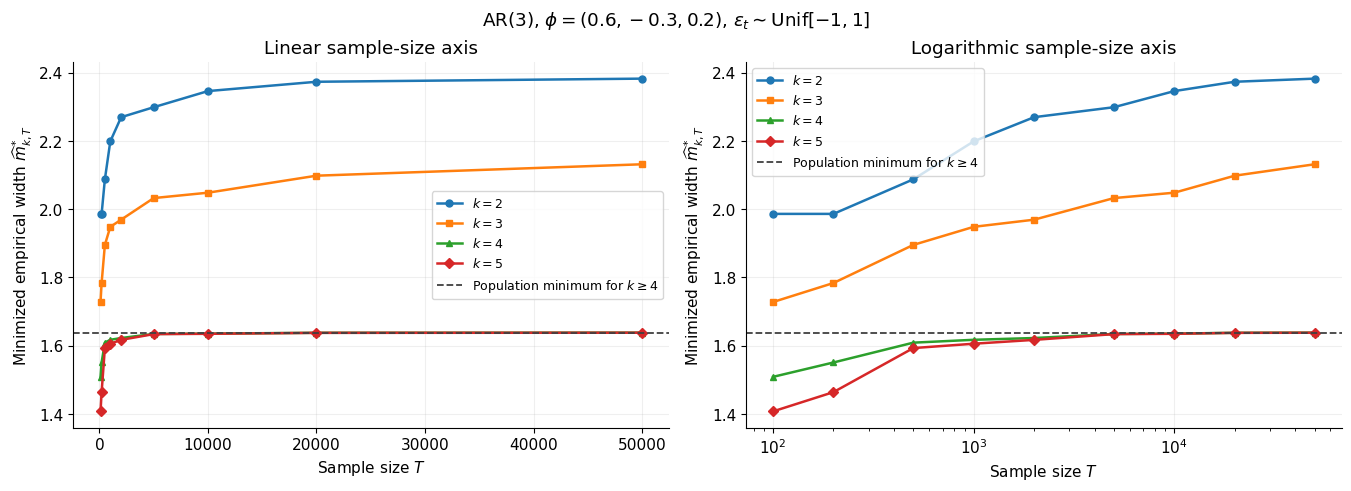

PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_minimum_width_vs_T/ar3_minimum_width_vs_T.pdf
CSV: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_minimum_width_vs_T/width_results.csv


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), constrained_layout=True)
colors = {int(k): plt.get_cmap("tab10")(index)
          for index, k in enumerate(k_values)}
markers = ["o", "s", "^", "D", "v", "P", "X"]

for ax in axes:
    for index, k in enumerate(k_values):
        ax.plot(
            width_table.index, width_table[int(k)],
            color=colors[int(k)], marker=markers[index % len(markers)],
            linewidth=1.8, markersize=5, label=fr"$k={k}$",
        )
    ax.axhline(
        population_plateau, color="0.25", linestyle="--", linewidth=1.3,
        label=r"Population minimum for $k\geq 4$",
    )
    ax.set_xlabel(r"Sample size $T$")
    ax.set_ylabel(r"Minimized empirical width $\widehat{m}^{*}_{k,T}$")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9, loc="best")
axes[0].set_title("Linear sample-size axis")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[1].set_title("Logarithmic sample-size axis")
axes[1].set_xscale("log")
fig.suptitle(
    fr"AR(3), $\phi=({phi[0]:g},{phi[1]:g},{phi[2]:g})$, "
    r"$\varepsilon_t\sim\mathrm{Unif}[-1,1]$"
)
figure_stem = "ar3_minimum_width_vs_T"
fig.savefig(PDF_DIR / f"{figure_stem}.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / f"{figure_stem}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"PDF: {PDF_DIR / (figure_stem + '.pdf')}")
print(f"CSV: {CSV_DIR / 'width_results.csv'}")

## Numerical diagnostics and interpretation

For fixed $k$, the exact empirical minimum is nondecreasing along nested point clouds. Independent finite-budget descent runs can violate that property if they find different local minima; the table and plot retain the raw estimates. The diagnostic below reports any downward steps and the benefit of extra starts rather than imposing monotonicity.

The population width evaluated at the estimated direction helps interpret the remaining gap: its difference from the empirical width measures how incompletely the sampled points fill the support in that direction. For $k=4,5$, compare it with the population reference to inspect how close the direction is to a population minimizer. A finite iteration budget does not establish convergence as $T$ tends to infinity. This is one sample-path experiment, not a Monte Carlo mean.

In [5]:
downward_steps = []
for k in k_values:
    values = width_table[int(k)].to_numpy()
    for index in np.flatnonzero(np.diff(values) < -1e-7):
        downward_steps.append({
            "k": int(k), "T_from": int(T_values[index]),
            "T_to": int(T_values[index + 1]),
            "width_change": float(values[index + 1] - values[index]),
        })
if downward_steps:
    print("Downward steps in the raw optimizer estimates:")
    display(pd.DataFrame(downward_steps))
else:
    print("No downward steps larger than 1e-7 in the raw width curves.")

final_diagnostics = width_results.loc[
    width_results["T"] == T_values[-1],
    ["k", "minimum_width", "covariance_start_width", "restart_improvement",
     "population_width_at_estimated_direction"],
].set_index("k")
print(f"Diagnostics at T = {T_values[-1]:,}:")
display(final_diagnostics.round(6))
print(f"Population reference for k >= 4: {population_plateau:.8f}")

No downward steps larger than 1e-7 in the raw width curves.
Diagnostics at T = 50,000:


,minimum_width,covariance_start_width,restart_improvement,population_width_at_estimated_direction
k,,,,
2,2.382370,2.382370,0.0,2.570012
3,2.131526,2.131526,0.0,2.342736
4,1.638390,1.638390,0.0,1.640126
5,1.638161,1.638161,0.0,1.639881


Population reference for k >= 4: 1.63846384


## Convergence speed: $T$ versus $|m_k-\widehat m_{k,T}|$

Use the optimized empirical widths above and compute the **absolute error relative to the population minimum** separately for every $k$:

$$e_k(T)=\left|m_k-\widehat m^{*}_{k,T}\right|.$$

For $k=4,5$, use the existing population formula. For $k=2,3$, numerically minimize the population support width of the finite-history AR zonotope. In two dimensions its minimum occurs at a generator normal; in three dimensions it occurs at a normal to a pair of independent generators. Enumerating these directions gives the finite-zonotope minimum, rather than evaluating population width at the empirical direction. Check it against twice the impulse-response history; this measures truncation sensitivity, not a rigorous bound on the infinite tail.

The second panel uses logarithmic axes: a power law $e_k(T)\approx CT^{-\alpha}$ appears as a line with slope $-\alpha$. The gray $T^{-1/2}$ and $T^{-1}$ lines are visual comparisons with an arbitrary common scale. The fitted exponents use the last five available sample sizes and describe this single path only. The plotted errors include sampling and finite-budget optimization effects; small errors can also result from cancellation between those effects.

In [6]:
from Code.Code_AR_processes.functions import ar_window_zonotope_generators


def population_minimum_low_dimension(phi, k, history, half_width):
    """Enumerate facet-normal candidates of a finite AR support zonotope."""
    if k not in (2, 3):
        raise ValueError("This population calculation supports k=2 or k=3.")
    generators = ar_window_zonotope_generators(
        phi, embedding_dimension=k, history=history, half_width=half_width,
    )
    unit_generators = generators / np.linalg.norm(generators, axis=0)
    if k == 2:
        candidates = np.column_stack((-unit_generators[1], unit_generators[0]))
    else:
        first, second = np.triu_indices(generators.shape[1], k=1)
        candidates = np.cross(
            unit_generators[:, first].T, unit_generators[:, second].T,
        )
    candidate_norms = np.linalg.norm(candidates, axis=1)
    independent = candidate_norms > 1e-12
    candidates = candidates[independent] / candidate_norms[independent, None]
    if len(candidates) == 0:
        raise RuntimeError("No nondegenerate population normal was found.")
    candidate_widths = 2.0 * np.abs(generators.T @ candidates.T).sum(axis=0)
    best = int(np.argmin(candidate_widths))
    direction = candidates[best]
    # Reevaluate through the shared population-width function so that the
    # reference retains its full impulse-response history.
    minimum = theoretical_ar_width_in_direction(
        phi, direction, half_width=half_width, history=history,
    )
    return minimum, direction


population_reference_history = max(1_000, int(population_history))
population_reference_rows = []
with threadpool_limits(limits=1):
    for k in k_values:
        k = int(k)
        if k < len(phi) + 1:
            minimum, _ = population_minimum_low_dimension(
                phi, k, population_reference_history, innovations_half_width,
            )
            longer_history_minimum, _ = population_minimum_low_dimension(
                phi, k, 2 * population_reference_history, innovations_half_width,
            )
            history_change = abs(longer_history_minimum - minimum)
            if history_change > 1e-9:
                raise RuntimeError(
                    f"Population reference for k={k} is sensitive to truncation; "
                    "increase population_reference_history."
                )
            minimum = longer_history_minimum
            method = "finite-zonotope normal enumeration"
        else:
            minimum = population_plateau
            history_change = 0.0
            method = "population formula"
        population_reference_rows.append({
            "k": k, "population_minimum": float(minimum),
            "history_doubling_change": float(history_change), "method": method,
        })

population_references = pd.DataFrame(population_reference_rows).set_index("k")
population_minima = population_references["population_minimum"]
convergence_results = width_results[["T", "k", "minimum_width"]].copy()
convergence_results["population_minimum"] = convergence_results["k"].map(population_minima)
convergence_results["absolute_error"] = np.abs(
    convergence_results["population_minimum"] - convergence_results["minimum_width"]
)
error_table = convergence_results.pivot(index="T", columns="k", values="absolute_error")
population_references.to_csv(CSV_DIR / "population_minimum_references.csv")
convergence_results.to_csv(CSV_DIR / "convergence_errors.csv", index=False)
error_table.to_csv(CSV_DIR / "absolute_error_vs_T.csv")
print("Population reference for each embedding dimension:")
display(population_references)
print("Absolute convergence errors:")
display(error_table.round(8))

Population reference for each embedding dimension:


,population_minimum,history_doubling_change,method
k,,,
2,2.532902,0.0,finite-zonotope normal enumeration
3,2.325273,0.0,finite-zonotope normal enumeration
4,1.638464,0.0,population formula
5,1.638464,0.0,population formula


Absolute convergence errors:


k,2,3,4,5
T,,,,
100,0.546675,0.597187,0.129573,0.230717
200,0.546675,0.541495,0.087453,0.174291
500,0.445463,0.429935,0.029403,0.045291
1000,0.334260,0.376976,0.021028,0.032523
2000,0.263436,0.356022,0.015851,0.021254
5000,0.234232,0.292733,0.003882,0.004356
10000,0.186968,0.276984,0.002971,0.003487
20000,0.159689,0.227177,0.000520,0.000674
50000,0.150532,0.193748,0.000074,0.000303


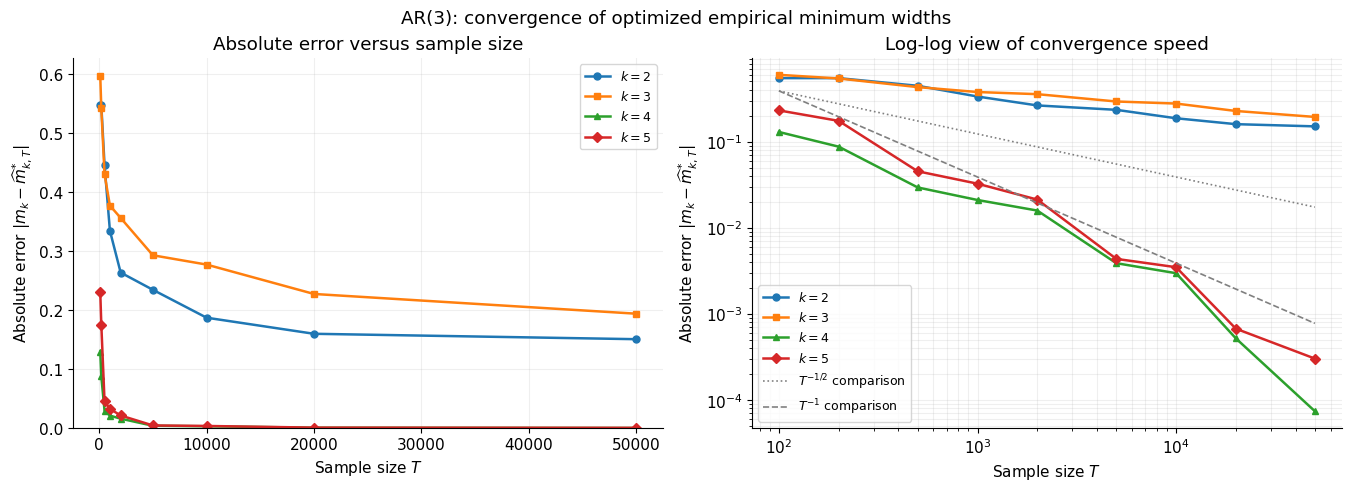

Descriptive power-law fit: error approximately C * T**(-alpha)
Single-path slopes include finite-budget optimization effects.


,k,fit_T_min,fit_T_max,fit_points,log_log_slope,descriptive_alpha
0,2,2000,50000,5,-0.1899,0.1899
1,3,2000,50000,5,-0.1881,0.1881
2,4,2000,50000,5,-1.6325,1.6325
3,5,2000,50000,5,-1.3245,1.3245


PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_minimum_width_vs_T/ar3_minimum_width_convergence_error.pdf


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), constrained_layout=True)
convergence_colors = {
    int(k): plt.get_cmap("tab10")(index) for index, k in enumerate(k_values)
}
convergence_markers = ["o", "s", "^", "D", "v", "P", "X"]

for index, k in enumerate(k_values):
    errors = error_table[int(k)].to_numpy()
    sample_sizes = error_table.index.to_numpy(dtype=float)
    label = fr"$k={k}$"
    style = dict(
        color=convergence_colors[int(k)],
        marker=convergence_markers[index % len(convergence_markers)],
        linewidth=1.8, markersize=5, label=label,
    )
    axes[0].plot(sample_sizes, errors, **style)
    # A zero cannot be displayed on logarithmic axes; retain it in the CSV
    # and linear panel rather than replacing it with a fabricated value.
    positive = errors > 0
    axes[1].loglog(sample_sizes[positive], errors[positive], **style)
    if np.any(~positive):
        print(f"k={k}: {np.count_nonzero(~positive)} zero errors omitted from log-log panel.")

first_errors = error_table.iloc[0].to_numpy()
positive_first_errors = first_errors[first_errors > 0]
if len(positive_first_errors):
    guide_scale = float(np.median(positive_first_errors))
    guide_T = np.geomspace(error_table.index.min(), error_table.index.max(), 200)
    for exponent, linestyle, label in (
        (0.5, ":", r"$T^{-1/2}$ comparison"),
        (1.0, "--", r"$T^{-1}$ comparison"),
    ):
        axes[1].loglog(
            guide_T, guide_scale * (guide_T / guide_T[0]) ** (-exponent),
            color="0.5", linestyle=linestyle, linewidth=1.2, label=label,
        )

for ax in axes:
    ax.set_xlabel(r"Sample size $T$")
    ax.set_ylabel(r"Absolute error $|m_k-\widehat{m}^{*}_{k,T}|$")
    ax.grid(which="both", alpha=0.2)
    ax.legend(fontsize=9, loc="best")
axes[0].set_title("Absolute error versus sample size")
axes[0].set_ylim(bottom=0)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[1].set_title("Log-log view of convergence speed")
fig.suptitle("AR(3): convergence of optimized empirical minimum widths")
convergence_figure_stem = "ar3_minimum_width_convergence_error"
fig.savefig(PDF_DIR / f"{convergence_figure_stem}.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / f"{convergence_figure_stem}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Descriptive least-squares slope on a configurable large-T window.
convergence_fit_points = 5
fit_rows = []
for k in k_values:
    tail_errors = error_table[int(k)].iloc[-convergence_fit_points:]
    tail_errors = tail_errors[tail_errors > 0]
    if len(tail_errors) < 2:
        continue
    log_T = np.log(tail_errors.index.to_numpy(dtype=float))
    log_error = np.log(tail_errors.to_numpy())
    slope, intercept = np.polyfit(log_T, log_error, deg=1)
    fit_rows.append({
        "k": int(k), "fit_T_min": int(tail_errors.index.min()),
        "fit_T_max": int(tail_errors.index.max()), "fit_points": len(tail_errors),
        "log_log_slope": float(slope), "descriptive_alpha": float(-slope),
    })
convergence_slopes = pd.DataFrame(fit_rows)
convergence_slopes.to_csv(CSV_DIR / "descriptive_convergence_slopes.csv", index=False)
print("Descriptive power-law fit: error approximately C * T**(-alpha)")
print("Single-path slopes include finite-budget optimization effects.")
display(convergence_slopes.round(4))
print(f"PDF: {PDF_DIR / (convergence_figure_stem + '.pdf')}")

## Coefficient norm versus sample size

The true AR(3) coefficient vector is fixed, so $\|\phi\|_2=0.7$ is constant. To show the effect of increasing $T$, recover the estimated coefficients from the minimum-width direction at $k=p+1=4$:

$$\widehat\phi_{j,T}=-\frac{\widehat u_{j,T}}{\widehat u_{0,T}},\quad j=1,2,3,\qquad
\|\widehat\phi_T\|_2=\sqrt{\sum_{j=1}^3\widehat\phi_{j,T}^{\,2}}.$$

Plot the estimated Euclidean norm against $T$, with the fixed true norm as a horizontal reference. Use only $k=4$, where all four coordinates correspond to the AR recurrence. At $k=5$ the recurrence can be shifted within the minimizing direction, so the same direct coordinate ratio is not generally valid. A close norm alone does not guarantee that each coefficient is accurate.

For comparison, estimate the same AR order $p=3$ by **Yule–Walker** on each prefix $X_1,\ldots,X_T$. Center that prefix using its own sample mean and use the autocovariance convention

$$\widehat\gamma_T(h)=\frac{1}{T}\sum_{t=h+1}^T(X_t-\overline X_T)(X_{t-h}-\overline X_T).$$

Solve the Toeplitz system $\widehat\Gamma_{p,T}\widehat\phi_T^{\mathrm{YW}}=(\widehat\gamma_T(1),\ldots,\widehat\gamma_T(p))^\top$, where $(\widehat\Gamma_{p,T})_{ij}=\widehat\gamma_T(|i-j|)$. The plot compares the estimated coefficient norms on the same simulated path and sample-size grid, with the true norm as reference.

Also fit **Gaussian conditional quasi-maximum likelihood (CQML)** to each prefix, conditioning on its first $p=3$ observations. Keep the intercept fixed at zero, as in the simulated AR model and the AR chapter. For $n_T=T-p$, maximize

$$\ell_T(\theta,\sigma^2)=-\frac{n_T}{2}\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{t=p+1}^T\left(X_t-\sum_{j=1}^p\theta_jX_{t-j}\right)^2.$$

The maximizing coefficients are the conditional least-squares solution, and $\widehat\sigma_T^2$ is the residual sum of squares divided by $n_T$. The plot adds $\|\widehat\phi_T^{\mathrm{CQML}}\|_2$. The table and CSV also retain $\widehat\sigma_T^2$ and the maximized conditional quasi-log-likelihood. It is a Gaussian quasi-likelihood because the simulated innovations are uniform.

Finally add **Horváth's $L^\infty$ linear-program estimator**, which jointly estimates the AR coefficients and the symmetric innovation half-width $h$. Keep the intercept fixed at zero and solve, on each full prefix,

$$\min_{\theta\in\mathbb R^p,\,h\ge0}h\quad\text{subject to}\quad
-h\le X_t-\sum_{j=1}^p\theta_jX_{t-j}\le h,\quad t=p+1,\ldots,T.$$

The AR coefficients use the sign convention $X_t=\sum_j\phi_jX_{t-j}+\varepsilon_t$. HiGHS solves the LP, with unrestricted coefficient bounds. Convex-hull vertices suffice for these linear residual constraints; the returned solution is checked against **all** observations, and its primal/dual objective gap is recorded. The plot adds the coefficient norm, while the table also records $\widehat h$. This fixes the current-observation coefficient at one, whereas the minimum-width method optimizes a directional range over unit vectors.

Reference: [Horváth (1989), AR models with uniformly distributed noise](https://dmlcz-proxy.ics.muni.cz/handle/10338.dmlcz/104367). Solver: [SciPy's HiGHS linear-programming interface](https://docs.scipy.org/doc/scipy/reference/optimize.linprog-highs.html).

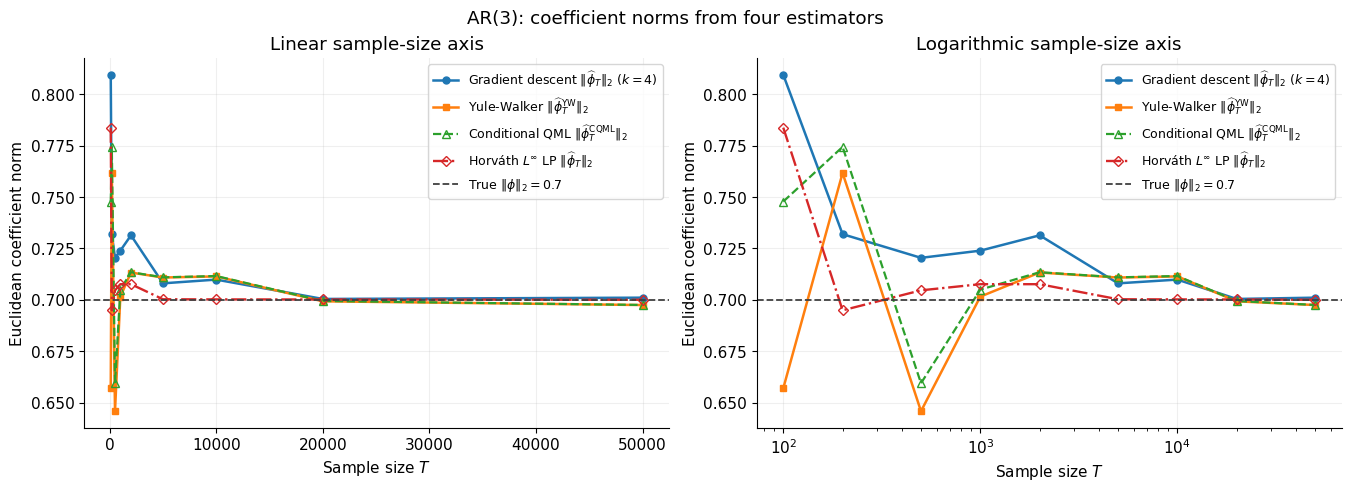

,T,k,estimated_phi_1,estimated_phi_2,estimated_phi_3,estimated_coefficient_norm,true_coefficient_norm,absolute_norm_error,yule_walker_phi_1,yule_walker_phi_2,...,conditional_qml_absolute_norm_error,conditional_qml_residual_variance,conditional_qml_log_likelihood,horvath_phi_1,horvath_phi_2,horvath_phi_3,horvath_coefficient_norm,horvath_absolute_norm_error,horvath_linf_radius,horvath_linf_duality_gap
2,100,4,0.679466,-0.368858,0.239925,0.809503,0.7,0.109503,0.491985,-0.290302,...,0.047828,0.336415,-84.800733,0.665366,-0.347643,0.225304,0.783792,0.083792,0.980964,0.0
6,200,4,0.629839,-0.326603,0.179957,0.731950,0.7,0.031950,0.638172,-0.357190,...,0.074417,0.342143,-173.887106,0.607104,-0.300227,0.155403,0.694882,0.005118,0.984905,0.0
10,500,4,0.610902,-0.317150,0.212684,0.720431,0.7,0.020431,0.550232,-0.286909,...,0.040607,0.333778,-432.538931,0.611322,-0.296356,0.186944,0.704620,0.004620,0.992705,0.0
14,1000,4,0.614079,-0.318971,0.212682,0.723927,0.7,0.023927,0.595029,-0.332497,...,0.004964,0.329512,-861.275314,0.607083,-0.303511,0.200100,0.707608,0.007608,0.996930,0.0
18,2000,4,0.617520,-0.321687,0.223869,0.731390,0.7,0.031390,0.613142,-0.321669,...,0.013436,0.333702,-1737.759340,0.607083,-0.303511,0.200100,0.707608,0.007608,0.996930,0.0
22,5000,4,0.604962,-0.304790,0.205957,0.708022,0.7,0.008022,0.612346,-0.307705,...,0.010940,0.327527,-4301.650726,0.600139,-0.300052,0.200455,0.700271,0.000271,0.999687,0.0
26,10000,4,0.606257,-0.306968,0.205177,0.709841,0.7,0.009841,0.607929,-0.310876,...,0.011587,0.330712,-8654.244865,0.599968,-0.300209,0.200499,0.700204,0.000204,0.999731,0.0
30,20000,4,0.600228,-0.300450,0.200098,0.700417,0.7,0.000417,0.601083,-0.296138,...,0.000564,0.334277,-17418.315773,0.599967,-0.300257,0.200279,0.700161,0.000161,0.999792,0.0
34,50000,4,0.600788,-0.300728,0.200196,0.701043,0.7,0.001043,0.598698,-0.298633,...,0.002505,0.332835,-43441.612111,0.600038,-0.299985,0.199975,0.700019,0.000019,0.999984,0.0


PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_minimum_width_vs_T/ar3_coefficient_norm_vs_T.pdf


In [8]:
from scipy.linalg import toeplitz
from scipy.optimize import linprog
from scipy.spatial import ConvexHull, QhullError


def yule_walker_coefficients(series, order):
    """Solve the centered Yule-Walker equations with denominator T."""
    series = np.asarray(series, dtype=float)
    if series.ndim != 1 or not np.all(np.isfinite(series)):
        raise ValueError("Use a finite one-dimensional time series.")
    if not 1 <= order < len(series):
        raise ValueError("Require 1 <= order < the sample size.")
    centered = series - np.mean(series)
    sample_size = len(centered)
    autocovariance = np.array([
        centered[lag:] @ centered[:sample_size - lag] / sample_size
        for lag in range(order + 1)
    ])
    if autocovariance[0] <= np.finfo(float).eps:
        raise ValueError("Cannot fit Yule-Walker coefficients to a constant series.")
    return np.linalg.solve(toeplitz(autocovariance[:-1]), autocovariance[1:])


def conditional_gaussian_qml(series, order):
    """Maximize the Gaussian conditional quasi-log-likelihood, intercept zero."""
    series = np.asarray(series, dtype=float)
    if series.ndim != 1 or not np.all(np.isfinite(series)):
        raise ValueError("Use a finite one-dimensional time series.")
    if not 1 <= order < len(series):
        raise ValueError("Require 1 <= order < the sample size.")
    windows = sliding_window_point_cloud(series, order + 1)
    response = windows[:, 0]
    lagged_values = windows[:, 1:]
    coefficients, _, rank, _ = np.linalg.lstsq(lagged_values, response, rcond=None)
    if rank < order:
        raise ValueError("The conditional regression design is rank deficient.")
    residuals = response - lagged_values @ coefficients
    residual_variance = float(residuals @ residuals / len(response))
    if residual_variance <= 0 or not np.isfinite(residual_variance):
        raise ValueError("A positive residual variance is required for the quasi-likelihood.")
    maximized_log_likelihood = float(
        -0.5 * len(response) * (np.log(2.0 * np.pi) + np.log(residual_variance) + 1.0)
    )
    return coefficients, residual_variance, maximized_log_likelihood


def horvath_linf_coefficients(series, order, use_convex_hull=True):
    """Estimate AR coefficients and symmetric noise half-width by an L-infinity LP."""
    series = np.asarray(series, dtype=float)
    if series.ndim != 1 or not np.all(np.isfinite(series)):
        raise ValueError("Use a finite one-dimensional time series.")
    if not 1 <= order < len(series):
        raise ValueError("Require 1 <= order < the sample size.")
    full_cloud = sliding_window_point_cloud(series, order + 1)
    constraint_cloud = full_cloud
    if use_convex_hull and len(full_cloud) > order + 1:
        try:
            hull = ConvexHull(full_cloud)
            constraint_cloud = full_cloud[np.sort(hull.vertices)]
        except QhullError:
            pass
    response = constraint_cloud[:, 0]
    lags = constraint_cloud[:, 1:]
    minus_ones = -np.ones(len(response))
    # Variables: (phi_1, ..., phi_p, h). Bound both signs of the residual.
    inequalities = np.vstack((
        np.column_stack((-lags, minus_ones)),
        np.column_stack((lags, minus_ones)),
    ))
    inequality_bounds = np.r_[-response, response]
    objective = np.r_[np.zeros(order), 1.0]
    result = linprog(
        objective, A_ub=inequalities, b_ub=inequality_bounds,
        bounds=[(None, None)] * order + [(0.0, None)], method="highs",
        options={"primal_feasibility_tolerance": 1e-9,
                 "dual_feasibility_tolerance": 1e-9},
    )
    if not result.success:
        raise RuntimeError(f"Horvath L-infinity LP failed: {result.message}")
    coefficients = result.x[:order]
    radius = float(result.x[-1])
    full_residuals = full_cloud[:, 0] - full_cloud[:, 1:] @ coefficients
    maximum_absolute_residual = float(np.max(np.abs(full_residuals)))
    dual_objective = float(inequality_bounds @ result.ineqlin.marginals)
    duality_gap = float(abs(radius - dual_objective))
    check_tolerance = 1e-8 * (1.0 + abs(radius))
    if (not np.all(np.isfinite(coefficients)) or not np.isfinite(radius)
            or not np.isfinite(duality_gap) or radius < 0
            or abs(maximum_absolute_residual - radius) > check_tolerance
            or duality_gap > check_tolerance):
        raise RuntimeError("Horvath LP failed its full-data feasibility or optimality check.")
    return coefficients, radius, duality_gap


coefficient_embedding_dimension = len(phi) + 1
coefficient_norm_results = width_results.loc[
    width_results["k"] == coefficient_embedding_dimension
].sort_values("T").copy()
if coefficient_norm_results.empty:
    raise ValueError("The coefficient-norm plot requires the k=p+1 embedding.")
coordinate_columns = [f"u_{j}" for j in range(coefficient_embedding_dimension)]
coefficient_directions = coefficient_norm_results[coordinate_columns].to_numpy()
if not np.all(np.isfinite(coefficient_directions)):
    raise ValueError("The saved coefficient directions must be finite.")
if np.any(np.abs(coefficient_directions[:, 0]) < 1e-10):
    raise ValueError("Cannot recover coefficients from a direction with near-zero u_0.")
estimated_coefficients = (
    -coefficient_directions[:, 1:] / coefficient_directions[:, [0]]
)
true_coefficient_norm = float(np.linalg.norm(phi))
coefficient_norm_results = coefficient_norm_results[["T", "k"]].copy()
for j in range(len(phi)):
    coefficient_norm_results[f"estimated_phi_{j + 1}"] = estimated_coefficients[:, j]
coefficient_norm_results["estimated_coefficient_norm"] = np.linalg.norm(
    estimated_coefficients, axis=1
)
coefficient_norm_results["true_coefficient_norm"] = true_coefficient_norm
coefficient_norm_results["absolute_norm_error"] = np.abs(
    coefficient_norm_results["estimated_coefficient_norm"] - true_coefficient_norm
)
# Fit Yule-Walker separately at each T; use only the corresponding prefix.
with threadpool_limits(limits=1):
    yule_walker_estimated_coefficients = np.vstack([
        yule_walker_coefficients(ar3_series[:int(T)], order=len(phi))
        for T in coefficient_norm_results["T"]
    ])
for j in range(len(phi)):
    coefficient_norm_results[f"yule_walker_phi_{j + 1}"] = (
        yule_walker_estimated_coefficients[:, j]
    )
coefficient_norm_results["yule_walker_coefficient_norm"] = np.linalg.norm(
    yule_walker_estimated_coefficients, axis=1
)
coefficient_norm_results["yule_walker_absolute_norm_error"] = np.abs(
    coefficient_norm_results["yule_walker_coefficient_norm"] - true_coefficient_norm
)
with threadpool_limits(limits=1):
    conditional_qml_fits = [
        conditional_gaussian_qml(ar3_series[:int(T)], order=len(phi))
        for T in coefficient_norm_results["T"]
    ]
conditional_qml_estimated_coefficients = np.vstack([fit[0] for fit in conditional_qml_fits])
for j in range(len(phi)):
    coefficient_norm_results[f"conditional_qml_phi_{j + 1}"] = (
        conditional_qml_estimated_coefficients[:, j]
    )
coefficient_norm_results["conditional_qml_coefficient_norm"] = np.linalg.norm(
    conditional_qml_estimated_coefficients, axis=1
)
coefficient_norm_results["conditional_qml_absolute_norm_error"] = np.abs(
    coefficient_norm_results["conditional_qml_coefficient_norm"] - true_coefficient_norm
)
coefficient_norm_results["conditional_qml_residual_variance"] = [
    fit[1] for fit in conditional_qml_fits
]
coefficient_norm_results["conditional_qml_log_likelihood"] = [
    fit[2] for fit in conditional_qml_fits
]
with threadpool_limits(limits=1):
    horvath_fits = [
        horvath_linf_coefficients(ar3_series[:int(T)], order=len(phi))
        for T in coefficient_norm_results["T"]
    ]
horvath_estimated_coefficients = np.vstack([fit[0] for fit in horvath_fits])
for j in range(len(phi)):
    coefficient_norm_results[f"horvath_phi_{j + 1}"] = horvath_estimated_coefficients[:, j]
coefficient_norm_results["horvath_coefficient_norm"] = np.linalg.norm(
    horvath_estimated_coefficients, axis=1
)
coefficient_norm_results["horvath_absolute_norm_error"] = np.abs(
    coefficient_norm_results["horvath_coefficient_norm"] - true_coefficient_norm
)
coefficient_norm_results["horvath_linf_radius"] = [fit[1] for fit in horvath_fits]
coefficient_norm_results["horvath_linf_duality_gap"] = [fit[2] for fit in horvath_fits]
coefficient_norm_results.to_csv(CSV_DIR / "coefficient_norm_vs_T.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), constrained_layout=True)
for ax in axes:
    ax.plot(
        coefficient_norm_results["T"],
        coefficient_norm_results["estimated_coefficient_norm"],
        color="tab:blue", marker="o", markersize=5, linewidth=1.8,
        label=fr"Gradient descent $\|\widehat{{\phi}}_T\|_2$ ($k={coefficient_embedding_dimension}$)",
    )
    ax.plot(
        coefficient_norm_results["T"],
        coefficient_norm_results["yule_walker_coefficient_norm"],
        color="tab:orange", marker="s", markersize=5, linewidth=1.8,
        label=r"Yule-Walker $\|\widehat{\phi}^{\mathrm{YW}}_T\|_2$",
    )
    ax.plot(
        coefficient_norm_results["T"],
        coefficient_norm_results["conditional_qml_coefficient_norm"],
        color="tab:green", marker="^", markerfacecolor="none", markersize=6,
        linewidth=1.6, linestyle="--",
        label=r"Conditional QML $\|\widehat{\phi}^{\mathrm{CQML}}_T\|_2$",
    )
    ax.plot(
        coefficient_norm_results["T"],
        coefficient_norm_results["horvath_coefficient_norm"],
        color="tab:red", marker="D", markerfacecolor="none", markersize=5,
        linewidth=1.7, linestyle="-.",
        label=r"Horváth $L^\infty$ LP $\|\widehat{\phi}_T\|_2$",
    )
    ax.axhline(
        true_coefficient_norm, color="0.25", linestyle="--", linewidth=1.3,
        label=fr"True $\|\phi\|_2={true_coefficient_norm:g}$",
    )
    ax.set_xlabel(r"Sample size $T$")
    ax.set_ylabel("Euclidean coefficient norm")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9, loc="best")
axes[0].set_title("Linear sample-size axis")
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[1].set_title("Logarithmic sample-size axis")
axes[1].set_xscale("log")
fig.suptitle("AR(3): coefficient norms from four estimators")
coefficient_norm_figure_stem = "ar3_coefficient_norm_vs_T"
fig.savefig(PDF_DIR / f"{coefficient_norm_figure_stem}.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / f"{coefficient_norm_figure_stem}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
display(coefficient_norm_results.round(6))
print(f"PDF: {PDF_DIR / (coefficient_norm_figure_stem + '.pdf')}")

## Repeated coefficient RMSE experiment

Compare **minimum-width gradient descent**, **Yule–Walker**, **Gaussian conditional QML**, and **Horváth $L^\infty$ LP** over $R=100$ independent AR(3) paths, holding the coefficients and innovation distribution fixed. For every replication, simulate one path of length $T_{\max}$ after burn-in and fit all four methods to its nested prefixes at the same sample sizes as above. The gradient-descent settings are unchanged, including its $k=4$ embedding and common endpoint $K=5$. Width and subgradient evaluations use convex-hull vertices for speed; interior points cannot affect directional extrema. Covariance initialization still uses the full cloud. Degenerate hulls fall back to the full cloud. Yule–Walker, QML, and Horváth LP use the full corresponding prefix with the conventions defined above. The true coefficients are used only to generate data and score estimates, never to initialize descent.

For method $a$, measure the **coefficient-vector RMSE**, rather than the error of its norm:

$$\operatorname{RMSE}_a(T)=\sqrt{\frac{1}{R}\sum_{r=1}^{R}\left\|\widehat\phi^{(r)}_{a,T}-\phi\right\|_2^2}.$$

There is no division by the number of coefficients: this is the root mean squared Euclidean error of the complete coefficient vector. Also report median and 90th-percentile Euclidean error, per-coefficient bias and RMSE, and the number of nonstationary estimates. Finite large errors are retained. If a fit fails or produces invalid coefficients, record it; the unconditional RMSE for that method and sample size is then unavailable rather than computed after silently dropping failures.

The shaded bands are 95% **Monte Carlo bootstrap intervals** for estimated RMSE. Resample entire replications, using the same bootstrap indices for every sample size and method, to preserve pairing and the dependence between nested prefixes. These bands describe simulation uncertainty, not confidence intervals for $\phi$. The final table compares paired mean squared errors; positive `gradient_descent_minus_comparator_mse` favors the comparator.

Completed replications are cached under a configuration-specific folder. Rerunning this block reuses matching results. Changes to coefficients, sample sizes, seeds, fit settings, or estimator source create a new cache. The number of workers and replications can be changed in the next cell.

Horváth LP uses the zero-intercept formulation defined above. Its fitted half-width and primal/dual gap are retained in the replication CSV. It is also included in the paired MSE comparisons with gradient descent.

In [9]:
import hashlib
import inspect
import os
from joblib import Parallel, delayed, parallel_config

rmse_replication_count = 100
rmse_T_values = T_values.copy()
rmse_phi = phi.copy()
rmse_burnin = burnin
rmse_half_width = innovations_half_width
rmse_k = len(rmse_phi) + 1
rmse_K = K
rmse_starts = number_of_starts
rmse_iterations = optimization_iterations
rmse_initial_step_scale = initial_step_scale
rmse_geometric_decay = geometric_decay
rmse_process_seed = 20260923
rmse_optimizer_seed = 20260924
rmse_bootstrap_seed = 20260925
rmse_bootstrap_count = 2_000
rmse_jobs = min(4, os.cpu_count() or 1)
rmse_resume = True
rmse_use_convex_hull = True

if rmse_replication_count < 2 or rmse_bootstrap_count < 2:
    raise ValueError("Use at least two replications and bootstrap samples.")
if (rmse_T_values.ndim != 1 or len(rmse_T_values) < 2
        or np.any(np.diff(rmse_T_values) <= 0)
        or rmse_T_values[0] <= max(rmse_K, 2 * len(rmse_phi))):
    raise ValueError("Use increasing sample sizes large enough for all fits.")
if not is_stationary(rmse_phi)[0] or rmse_K < rmse_k:
    raise ValueError("Use stationary coefficients and K >= p+1.")
if rmse_starts < 1 or rmse_iterations < 1 or rmse_jobs < 1:
    raise ValueError("Use positive optimizer budgets and worker counts.")
if rmse_initial_step_scale <= 0 or not 0 < rmse_geometric_decay < 1:
    raise ValueError("Invalid descent step-size settings.")

RMSE_METHODS = ["Gradient descent", "Yule-Walker", "Conditional QML", "Horvath L-infinity LP"]
RMSE_DIR = CSV_DIR / "repeated_rmse"
RMSE_DIR.mkdir(parents=True, exist_ok=True)
# Include the shared optimizer/simulator and all local estimator definitions.
rmse_estimator_source = (
    (AR_CODE_DIR / "functions.py").read_bytes()
    + (AR_CODE_DIR / "descent.py").read_bytes()
    + inspect.getsource(yule_walker_coefficients).encode()
    + inspect.getsource(conditional_gaussian_qml).encode()
    + inspect.getsource(horvath_linf_coefficients).encode()
)
rmse_configuration = {
    "experiment_version": 3,
    "use_convex_hull": rmse_use_convex_hull,
    "replication_count": rmse_replication_count,
    "phi": rmse_phi.tolist(), "T_values": rmse_T_values.tolist(),
    "burnin": rmse_burnin, "half_width": rmse_half_width,
    "k": rmse_k, "K": rmse_K, "starts": rmse_starts,
    "iterations": rmse_iterations, "initial_step_scale": rmse_initial_step_scale,
    "geometric_decay": rmse_geometric_decay,
    "process_seed": rmse_process_seed, "optimizer_seed": rmse_optimizer_seed,
    "bootstrap_seed": rmse_bootstrap_seed, "bootstrap_count": rmse_bootstrap_count,
    "estimator_source_sha256": hashlib.sha256(rmse_estimator_source).hexdigest(),
    "invalid_u_0_threshold": 1e-10,
    "methods": RMSE_METHODS,
}
rmse_configuration_text = json.dumps(rmse_configuration, sort_keys=True, indent=2)
rmse_configuration_id = hashlib.sha256(rmse_configuration_text.encode()).hexdigest()[:16]
RMSE_CACHE_DIR = RMSE_DIR / "replications" / rmse_configuration_id
RMSE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
(RMSE_CACHE_DIR / "configuration.json").write_text(rmse_configuration_text + "\n")
print(f"Replications: {rmse_replication_count}; sample sizes: {rmse_T_values}")
print(f"Fixed coefficients: {rmse_phi}; workers: {rmse_jobs}")
print(f"Descent: {rmse_starts} starts, {rmse_iterations} iterations per start")
print(f"Configuration ID: {rmse_configuration_id}")

Replications: 100; sample sizes: [  100   200   500  1000  2000  5000 10000 20000 50000]
Fixed coefficients: [ 0.6 -0.3  0.2]; workers: 4
Descent: 12 starts, 3000 iterations per start
Configuration ID: 0889ba9acd3ce014


In [10]:
def run_rmse_replication(replication, configuration, cache_directory, resume=True):
    """Fit all four methods to one independently seeded, nested sample path."""
    cache_path = Path(cache_directory) / f"replication_{replication:04d}.csv"
    expected_rows = len(configuration["T_values"]) * len(configuration["methods"])
    if resume and cache_path.exists():
        cached = pd.read_csv(cache_path)
        if (len(cached) == expected_rows
                and not cached.duplicated(["T", "method"]).any()
                and (cached["replication"] == replication).all()
                and set(cached["T"]) == set(configuration["T_values"])
                and set(cached["method"]) == set(configuration["methods"])):
            return cached
        raise RuntimeError(f"Incomplete or inconsistent cache: {cache_path}")

    true_phi = np.asarray(configuration["phi"], dtype=float)
    order = len(true_phi)
    k = configuration["k"]
    common_K = configuration["K"]
    process_generator = np.random.default_rng(np.random.SeedSequence([
        configuration["process_seed"], replication,
    ]))
    rows = []
    with threadpool_limits(limits=1):
        series = simulate_uniform_ar(
            true_phi, sample_size=max(configuration["T_values"]),
            burnin=configuration["burnin"], half_width=configuration["half_width"],
            rng=process_generator,
        )
        for T in configuration["T_values"]:
            prefix = series[:T]
            for method in configuration["methods"]:
                start_time = perf_counter()
                extra = {"minimum_width": np.nan, "abs_u_0": np.nan,
                         "residual_variance": np.nan, "quasi_log_likelihood": np.nan,
                         "linf_radius": np.nan, "linf_duality_gap": np.nan}
                estimate = np.full(order, np.nan)
                status, error_message = "ok", ""
                try:
                    if method == "Gradient descent":
                        series_for_k = prefix[common_K - k:]
                        cloud = sliding_window_point_cloud(series_for_k, k)
                        lipschitz_bound = float(np.linalg.norm(np.ptp(cloud, axis=0)))
                        if not np.isfinite(lipschitz_bound) or lipschitz_bound <= 0:
                            raise ValueError("Invalid Lipschitz upper bound.")
                        _, widths, _, directions = batched_geometric_width_curves(
                            series_for_k, [k], seed=configuration["optimizer_seed"],
                            replication=replication - 1,
                            starts=configuration["starts"], iterations=configuration["iterations"],
                            initial_step=configuration["initial_step_scale"] / lipschitz_bound,
                            geometric_decay=configuration["geometric_decay"],
                            return_directions=True, use_convex_hull=configuration["use_convex_hull"],
                        )
                        direction = directions[0]
                        extra["minimum_width"] = float(widths[0])
                        extra["abs_u_0"] = float(abs(direction[0]))
                        if not np.isclose(np.linalg.norm(direction), 1.0, atol=1e-10):
                            raise RuntimeError("The descent direction is not a unit vector.")
                        if not np.isclose(np.ptp(cloud @ direction), widths[0], atol=1e-10):
                            raise RuntimeError("The direction does not reproduce its width.")
                        if abs(direction[0]) < configuration["invalid_u_0_threshold"]:
                            raise ValueError("Cannot recover coefficients: near-zero u_0.")
                        estimate = -direction[1:] / direction[0]
                    elif method == "Yule-Walker":
                        estimate = yule_walker_coefficients(prefix, order)
                    elif method == "Conditional QML":
                        estimate, variance, log_likelihood = conditional_gaussian_qml(prefix, order)
                        extra["residual_variance"] = variance
                        extra["quasi_log_likelihood"] = log_likelihood
                    elif method == "Horvath L-infinity LP":
                        estimate, radius, duality_gap = horvath_linf_coefficients(
                            prefix, order, use_convex_hull=configuration["use_convex_hull"],
                        )
                        extra["linf_radius"] = radius
                        extra["linf_duality_gap"] = duality_gap
                    else:
                        raise ValueError(f"Unknown method: {method}")
                    if estimate.shape != true_phi.shape or not np.all(np.isfinite(estimate)):
                        raise ValueError("The coefficient estimate is invalid.")
                    errors = estimate - true_phi
                    squared_error = float(errors @ errors)
                    if not np.isfinite(squared_error):
                        raise ValueError("The squared coefficient error is not finite.")
                    estimated_stationary = bool(is_stationary(estimate)[0])
                except Exception as exc:
                    status, error_message = "failed", f"{type(exc).__name__}: {exc}"
                    errors = np.full(order, np.nan)
                    squared_error = np.nan
                    estimated_stationary = np.nan
                elapsed = perf_counter() - start_time
                row = {
                    "replication": replication, "T": T, "method": method,
                    "status": status, "error_message": error_message,
                    "squared_coefficient_error": squared_error,
                    "coefficient_error": float(np.sqrt(squared_error)),
                    "estimated_coefficient_norm": float(np.linalg.norm(estimate)),
                    "estimated_stationary": estimated_stationary,
                    "runtime_seconds": elapsed, **extra,
                }
                for j in range(order):
                    row[f"estimated_phi_{j + 1}"] = float(estimate[j])
                    row[f"phi_error_{j + 1}"] = float(errors[j])
                rows.append(row)
    result = pd.DataFrame(rows)
    temporary_path = cache_path.with_suffix(f".tmp.{os.getpid()}")
    result.to_csv(temporary_path, index=False)
    temporary_path.replace(cache_path)
    return result


rmse_run_start = perf_counter()
rmse_replication_frames = []
# Each worker fits one whole replication; NumPy uses one BLAS thread per worker.
with parallel_config(backend="loky", inner_max_num_threads=1):
    completed_replications = Parallel(n_jobs=rmse_jobs, return_as="generator_unordered")(
        delayed(run_rmse_replication)(
            replication, rmse_configuration, str(RMSE_CACHE_DIR), rmse_resume,
        )
        for replication in range(1, rmse_replication_count + 1)
    )
    for count, result in enumerate(completed_replications, start=1):
        rmse_replication_frames.append(result)
        if count == 1 or count % 10 == 0 or count == rmse_replication_count:
            checkpoint = pd.concat(rmse_replication_frames, ignore_index=True)
            checkpoint.to_csv(RMSE_DIR / "replication_results_partial.csv", index=False)
            print(f"Completed {count}/{rmse_replication_count} replications; "
                  f"elapsed {(perf_counter() - rmse_run_start) / 60:.1f} minutes", flush=True)

rmse_replication_results = pd.concat(rmse_replication_frames, ignore_index=True).sort_values(
    ["replication", "T", "method"]
).reset_index(drop=True)
expected_count = rmse_replication_count * len(rmse_T_values) * len(RMSE_METHODS)
if (len(rmse_replication_results) != expected_count
        or rmse_replication_results.duplicated(["replication", "T", "method"]).any()):
    raise RuntimeError("The paired Monte Carlo results are incomplete or duplicated.")
rmse_replication_results.to_csv(RMSE_DIR / "replication_results.csv", index=False)
(RMSE_DIR / "configuration.json").write_text(rmse_configuration_text + "\n")
rmse_failures = rmse_replication_results.loc[rmse_replication_results["status"] != "ok"]
rmse_failures.to_csv(RMSE_DIR / "failed_fits.csv", index=False)
print(f"Completed {expected_count:,} fits in {(perf_counter() - rmse_run_start) / 60:.1f} minutes")
print(f"Failed fits: {len(rmse_failures)}; finite large errors are retained.")
if len(rmse_failures):
    display(rmse_failures[["replication", "T", "method", "error_message"]])

Completed 1/100 replications; elapsed 0.1 minutes


Completed 10/100 replications; elapsed 0.2 minutes


Completed 20/100 replications; elapsed 0.3 minutes


Completed 30/100 replications; elapsed 0.4 minutes


Completed 40/100 replications; elapsed 0.5 minutes


Completed 50/100 replications; elapsed 0.6 minutes


... (2 outputs left out)

Completed 80/100 replications; elapsed 0.9 minutes


Completed 90/100 replications; elapsed 1.0 minutes


Completed 100/100 replications; elapsed 1.1 minutes


Completed 3,600 fits in 1.1 minutes
Failed fits: 0; finite large errors are retained.


In [11]:
rmse_columns = pd.MultiIndex.from_product([rmse_T_values, RMSE_METHODS], names=["T", "method"])
rmse_loss_matrix = rmse_replication_results.pivot(
    index="replication", columns=["T", "method"], values="squared_coefficient_error"
).reindex(index=range(1, rmse_replication_count + 1), columns=rmse_columns).to_numpy()
bootstrap_generator = np.random.default_rng(rmse_bootstrap_seed)
rmse_bootstrap_indices = bootstrap_generator.integers(
    0, rmse_replication_count, size=(rmse_bootstrap_count, rmse_replication_count)
)
# Ordinary means preserve any failed (NaN) fit; no success-only RMSE is substituted.
rmse_bootstrap_means = np.mean(rmse_loss_matrix[rmse_bootstrap_indices], axis=1)
rmse_bootstrap_values = np.sqrt(rmse_bootstrap_means)
rmse_bootstrap_lower, rmse_bootstrap_upper = np.quantile(
    rmse_bootstrap_values, [0.025, 0.975], axis=0
)

summary_rows = []
for column, (T, method) in enumerate(rmse_columns):
    group = rmse_replication_results.loc[
        (rmse_replication_results["T"] == T) & (rmse_replication_results["method"] == method)
    ]
    failed_count = int((group["status"] != "ok").sum())
    losses = group["squared_coefficient_error"].to_numpy()
    euclidean_errors = group["coefficient_error"].to_numpy()
    unconditional_mse = float(np.mean(losses))
    row = {
        "T": int(T), "method": method, "replications": len(group),
        "failed_fits": failed_count, "mse": unconditional_mse,
        "rmse": float(np.sqrt(unconditional_mse)),
        "rmse_mc_se": float(np.std(rmse_bootstrap_values[:, column], ddof=1)) if not failed_count else np.nan,
        "rmse_ci_lower": float(rmse_bootstrap_lower[column]) if not failed_count else np.nan,
        "rmse_ci_upper": float(rmse_bootstrap_upper[column]) if not failed_count else np.nan,
        "median_coefficient_error": float(np.median(euclidean_errors)),
        "q90_coefficient_error": float(np.quantile(euclidean_errors, 0.9)),
        "large_error_count_above_1": int(np.count_nonzero(euclidean_errors > 1)),
        "nonstationary_estimates": int((group["estimated_stationary"] == False).sum()),
        "mean_runtime_seconds": float(group["runtime_seconds"].mean()),
    }
    for j in range(len(rmse_phi)):
        errors_j = group[f"phi_error_{j + 1}"].to_numpy()
        row[f"phi_{j + 1}_bias"] = float(np.mean(errors_j))
        row[f"phi_{j + 1}_rmse"] = float(np.sqrt(np.mean(errors_j**2)))
    summary_rows.append(row)
rmse_summary = pd.DataFrame(summary_rows)
rmse_summary.to_csv(RMSE_DIR / "rmse_summary.csv", index=False)

paired_rows = []
for T in rmse_T_values:
    gd_column = rmse_columns.get_loc((T, "Gradient descent"))
    for comparator in (method for method in RMSE_METHODS if method != "Gradient descent"):
        comparator_column = rmse_columns.get_loc((T, comparator))
        differences = rmse_loss_matrix[:, gd_column] - rmse_loss_matrix[:, comparator_column]
        bootstrap_differences = (
            rmse_bootstrap_means[:, gd_column] - rmse_bootstrap_means[:, comparator_column]
        )
        all_valid = bool(np.all(np.isfinite(differences)))
        paired_rows.append({
            "T": int(T), "comparator": comparator,
            "gradient_descent_minus_comparator_mse": float(np.mean(differences)),
            "mc_se_mse_difference": float(np.std(differences, ddof=1) / np.sqrt(len(differences))),
            "difference_ci_lower": float(np.quantile(bootstrap_differences, 0.025)) if all_valid else np.nan,
            "difference_ci_upper": float(np.quantile(bootstrap_differences, 0.975)) if all_valid else np.nan,
            "gd_lower_error_replications": int(np.count_nonzero(differences < 0)) if all_valid else np.nan,
            "valid_pairs": int(np.count_nonzero(np.isfinite(differences))),
        })
rmse_paired_comparison = pd.DataFrame(paired_rows)
rmse_paired_comparison.to_csv(RMSE_DIR / "paired_mse_comparisons.csv", index=False)
print("Coefficient-vector RMSE (all replications):")
display(rmse_summary.pivot(index="T", columns="method", values="rmse").round(6))
print("Monte Carlo uncertainty and error-distribution diagnostics at the largest T:")
display(rmse_summary.loc[rmse_summary["T"] == rmse_T_values[-1], [
    "method", "rmse", "rmse_ci_lower", "rmse_ci_upper", "failed_fits",
    "median_coefficient_error", "q90_coefficient_error", "nonstationary_estimates",
]].round(6))

Coefficient-vector RMSE (all replications):


method,Conditional QML,Gradient descent,Horvath L-infinity LP,Yule-Walker
T,,,,
100,0.190680,13.586402,0.085332,0.186425
200,0.128863,0.838515,0.042732,0.126398
500,0.081047,0.860868,0.014521,0.079990
1000,0.055500,0.083419,0.007234,0.055423
2000,0.038326,0.018629,0.004447,0.038212
5000,0.024995,0.007056,0.001470,0.025022
10000,0.018903,0.003126,0.000779,0.018921
20000,0.013303,0.001916,0.000370,0.013303
50000,0.007917,0.000690,0.000161,0.007915


Monte Carlo uncertainty and error-distribution diagnostics at the largest T:


,method,rmse,rmse_ci_lower,rmse_ci_upper,failed_fits,median_coefficient_error,q90_coefficient_error,nonstationary_estimates
32,Gradient descent,0.000690,0.000561,0.000807,0,0.000387,0.001076,0
33,Yule-Walker,0.007915,0.007258,0.008516,0,0.006796,0.011457,0
34,Conditional QML,0.007917,0.007261,0.008516,0,0.006822,0.011466,0
35,Horvath L-infinity LP,0.000161,0.000140,0.000179,0,0.000109,0.000262,0


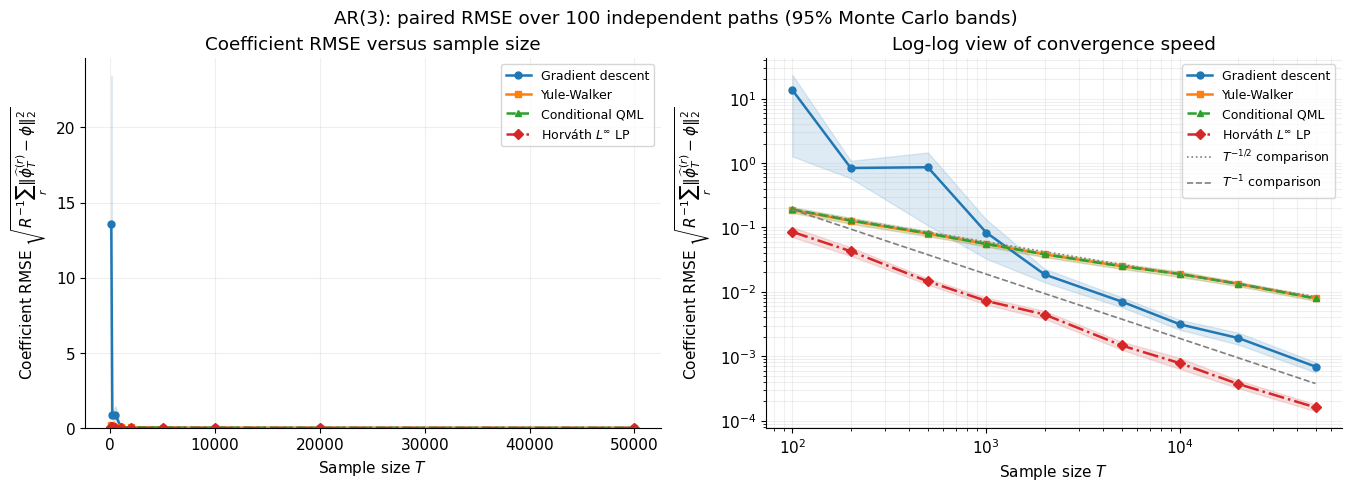

Paired mean squared error comparisons at the largest T (negative favors gradient descent):


,T,comparator,gradient_descent_minus_comparator_mse,mc_se_mse_difference,difference_ci_lower,difference_ci_upper,gd_lower_error_replications,valid_pairs
24,50000,Yule-Walker,-6.217000e-05,5.110000e-06,-7.211000e-05,-5.217000e-05,100,100
25,50000,Conditional QML,-6.221000e-05,5.110000e-06,-7.212000e-05,-5.218000e-05,100,100
26,50000,Horvath L-infinity LP,4.500000e-07,9.000000e-08,2.900000e-07,6.300000e-07,6,100


PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_minimum_width_vs_T/ar3_repeated_coefficient_rmse_vs_T.pdf
Detailed results: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_minimum_width_vs_T/repeated_rmse/replication_results.csv


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), constrained_layout=True)
rmse_colors = {"Gradient descent": "tab:blue", "Yule-Walker": "tab:orange",
               "Conditional QML": "tab:green", "Horvath L-infinity LP": "tab:red"}
rmse_markers = {"Gradient descent": "o", "Yule-Walker": "s", "Conditional QML": "^", "Horvath L-infinity LP": "D"}

for method in RMSE_METHODS:
    values = rmse_summary.loc[rmse_summary["method"] == method].sort_values("T")
    valid = np.isfinite(values["rmse"]) & (values["rmse"] > 0)
    if not valid.all():
        print(f"{method}: {int((~valid).sum())} unavailable or zero RMSE values omitted from log-log view.")
    for panel, ax in enumerate(axes):
        plotted = values if panel == 0 else values.loc[valid]
        ax.plot(
            plotted["T"], plotted["rmse"], color=rmse_colors[method],
            marker=rmse_markers[method], linewidth=1.8, markersize=5,
            linestyle={"Conditional QML": "--", "Horvath L-infinity LP": "-."}.get(method, "-"),
            label=r"Horváth $L^\infty$ LP" if method == "Horvath L-infinity LP" else method,
        )
        ax.fill_between(
            plotted["T"].to_numpy(), plotted["rmse_ci_lower"].to_numpy(),
            plotted["rmse_ci_upper"].to_numpy(), color=rmse_colors[method], alpha=0.14,
        )

first_rmse = rmse_summary.loc[rmse_summary["T"] == rmse_T_values[0], "rmse"].to_numpy()
first_rmse = first_rmse[np.isfinite(first_rmse) & (first_rmse > 0)]
if len(first_rmse):
    guide_T = np.geomspace(rmse_T_values[0], rmse_T_values[-1], 200)
    guide_scale = float(np.median(first_rmse))
    for exponent, linestyle, label in (
        (0.5, ":", r"$T^{-1/2}$ comparison"), (1.0, "--", r"$T^{-1}$ comparison")
    ):
        axes[1].plot(
            guide_T, guide_scale * (guide_T / guide_T[0]) ** (-exponent),
            color="0.5", linestyle=linestyle, linewidth=1.2, label=label,
        )
for ax in axes:
    ax.set_xlabel(r"Sample size $T$")
    ax.set_ylabel(r"Coefficient RMSE $\sqrt{R^{-1}\sum_r\|\widehat{\phi}^{(r)}_T-\phi\|_2^2}$")
    ax.grid(which="both", alpha=0.2)
    ax.legend(fontsize=9, loc="best")
axes[0].set_title("Coefficient RMSE versus sample size")
axes[0].set_ylim(bottom=0)
axes[0].ticklabel_format(axis="x", style="plain", useOffset=False)
axes[1].set_title("Log-log view of convergence speed")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
fig.suptitle(fr"AR(3): paired RMSE over {rmse_replication_count} independent paths (95% Monte Carlo bands)")
rmse_figure_stem = "ar3_repeated_coefficient_rmse_vs_T"
fig.savefig(PDF_DIR / f"{rmse_figure_stem}.pdf", bbox_inches="tight")
fig.savefig(IMAGE_DIR / f"{rmse_figure_stem}.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Paired mean squared error comparisons at the largest T (negative favors gradient descent):")
display(rmse_paired_comparison.loc[rmse_paired_comparison["T"] == rmse_T_values[-1]].round(8))
print(f"PDF: {PDF_DIR / (rmse_figure_stem + '.pdf')}")
print(f"Detailed results: {RMSE_DIR / 'replication_results.csv'}")